# Detection criteria and lightcurve quality analysis

This notebook analyzes outputs produced by `scripts/run_detection_criteria_sweep.sh`. It does not run simulations.

In [1]:
from pathlib import Path
import json
import re
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('results/detection_criteria_sweep_v2')
QUALITY = ROOT / 'lightcurve_quality.csv'
if not QUALITY.exists():
    raise FileNotFoundError(f'Run lightcurve_quality_analysis.py first: {QUALITY}')
quality = pd.read_csv(QUALITY)
quality.head()

,file,source_index,z,t_exp,n_positive,n_non_detections,n_bands,bands,duplicate_positive_times,positive_span_days,...,positive_span_exceeds_14_days,all_observation_span_exceeds_14_days,criteria_snr_threshold,criteria_snr_threshold_secondary,criteria_min_detections,criteria_min_detections_primary,criteria_min_time_separation_hours,criteria_min_fade_rate,criteria_min_galactic_lat,band_counts
0,results/detection_criteria_sweep_v2/snr4_snr22...,0,0.03534,59871.616,7,90,3,g;i;r,0,2.03736,...,False,True,4.0,2.0,2,1,12.0,0.3,0.0,"{""g"": 2, ""i"": 2, ""r"": 3}"
1,results/detection_criteria_sweep_v2/snr4_snr22...,1,0.04229,61026.041,6,83,2,g;r,0,1.06127,...,False,True,4.0,2.0,2,1,12.0,0.3,0.0,"{""g"": 1, ""r"": 5}"
2,results/detection_criteria_sweep_v2/snr4_snr22...,2,0.03206,59224.126,13,191,3,g;i;r,0,2.09232,...,False,True,4.0,2.0,2,1,12.0,0.3,0.0,"{""g"": 5, ""i"": 1, ""r"": 7}"
3,results/detection_criteria_sweep_v2/snr4_snr22...,3,0.02906,60545.121,3,73,2,i;r,0,1.87248,...,False,True,4.0,2.0,2,1,12.0,0.3,0.0,"{""i"": 1, ""r"": 2}"
4,results/detection_criteria_sweep_v2/snr4_snr22...,4,0.06205,59376.024,4,106,2,g;r,0,1.01815,...,False,True,4.0,2.0,2,1,12.0,0.3,0.0,"{""g"": 1, ""r"": 3}"


## Lightcurve quality

The configured span is the detector's qualifying window. The all-observation span is reported separately because stored non-detections may extend beyond that window.

In [2]:
numeric = [
    'n_positive', 'n_non_detections', 'n_bands', 'duplicate_positive_times',
    'positive_span_days', 'all_observation_span_days', 'max_positive_gap_days',
    'min_positive_gap_days', 'configured_max_timespan_days'
]
quality[numeric] = quality[numeric].apply(pd.to_numeric, errors='coerce')
quality['positive_span_exceeds_configured_days'] = quality['positive_span_exceeds_configured_days'].astype(bool)
quality['all_observation_span_exceeds_configured_days'] = quality['all_observation_span_exceeds_configured_days'].astype(bool)
quality[numeric].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).T

,count,mean,std,min,50%,90%,95%,99%,max
n_positive,397529.0,8.449024,10.378369,2.00000,7.00000,14.000000,18.000000,30.000000,860.00000
n_non_detections,397529.0,140.900568,99.285542,0.00000,113.00000,272.000000,341.000000,482.000000,1503.00000
n_bands,397529.0,2.232793,0.635086,1.00000,2.00000,3.000000,3.000000,3.000000,3.00000
duplicate_positive_times,397529.0,0.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,0.00000
positive_span_days,397529.0,1.470924,0.680541,0.12501,1.09989,2.104832,2.957442,3.184210,10.99350
all_observation_span_days,397529.0,50.938845,6.769392,1.00045,53.79865,55.031640,55.095814,55.966794,57.10985
max_positive_gap_days,397529.0,1.033752,0.383759,0.00049,0.96054,1.843958,1.962370,2.045684,6.96445
min_positive_gap_days,397529.0,0.025979,0.144620,0.00015,0.00093,0.036760,0.058180,0.969020,5.00219
configured_max_timespan_days,397529.0,11.372627,6.843780,3.00000,14.00000,21.000000,21.000000,21.000000,21.00000


In [3]:
quality_summary = (
    quality.groupby([
        'criteria_snr_threshold', 'criteria_snr_threshold_secondary',
        'criteria_min_detections', 'criteria_min_detections_primary',
        'configured_max_timespan_days', 'criteria_min_time_separation_hours',
        'criteria_min_fade_rate', 'criteria_min_galactic_lat',
    ], dropna=False)
    .agg(
        sources=('source_index', 'size'),
        median_positive_span_days=('positive_span_days', 'median'),
        p95_positive_span_days=('positive_span_days', lambda values: values.quantile(0.95)),
        median_max_gap_days=('max_positive_gap_days', 'median'),
        positive_span_violations=('positive_span_exceeds_configured_days', 'sum'),
        all_span_violations=('all_observation_span_exceeds_configured_days', 'sum'),
        duplicate_time_sources=('duplicate_positive_times', lambda values: (values > 0).sum()),
    )
    .reset_index()
)
quality_summary.sort_values('positive_span_violations', ascending=False).head(20)

,criteria_snr_threshold,criteria_snr_threshold_secondary,criteria_min_detections,criteria_min_detections_primary,configured_max_timespan_days,criteria_min_time_separation_hours,criteria_min_fade_rate,criteria_min_galactic_lat,sources,median_positive_span_days,p95_positive_span_days,median_max_gap_days,positive_span_violations,all_span_violations,duplicate_time_sources
0,4.0,2.0,2,1,3.0,3.0,0.0,0.0,348,1.089155,2.101977,0.968685,0,348,0
1,4.0,2.0,2,1,3.0,3.0,0.0,15.0,257,1.073300,2.108518,0.958620,0,257,0
2,4.0,2.0,2,1,3.0,3.0,0.3,0.0,335,1.080880,2.100375,0.960770,0,335,0
3,4.0,2.0,2,1,3.0,3.0,0.3,15.0,256,1.077625,2.120892,0.961035,0,256,0
4,4.0,2.0,2,1,3.0,3.0,0.6,0.0,239,1.110660,2.139600,0.954720,0,239,0
5,4.0,2.0,2,1,3.0,3.0,0.6,15.0,169,1.097140,2.091744,0.958800,0,169,0
6,4.0,2.0,2,1,3.0,12.0,0.0,0.0,314,1.077560,2.107788,0.962915,0,314,0
7,4.0,2.0,2,1,3.0,12.0,0.0,15.0,304,1.074405,2.118199,0.966300,0,304,0
8,4.0,2.0,2,1,3.0,12.0,0.3,0.0,301,1.070210,2.090600,0.961660,0,301,0
9,4.0,2.0,2,1,3.0,12.0,0.3,15.0,255,1.077940,2.139329,0.958540,0,255,0


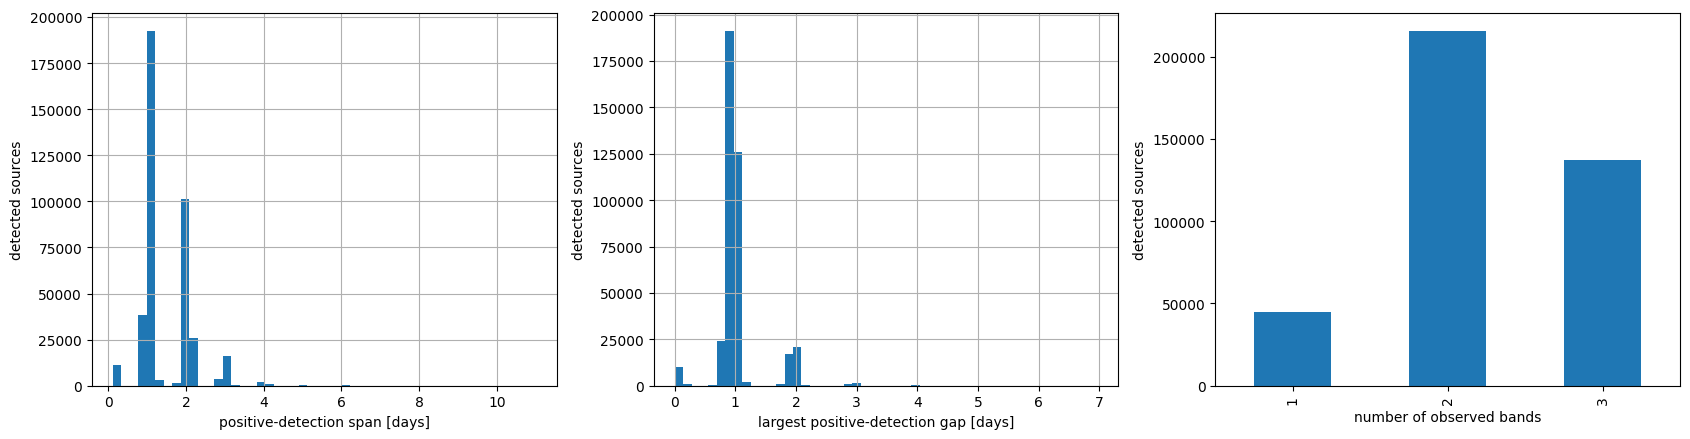

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
quality['positive_span_days'].hist(ax=axes[0], bins=50)
axes[0].set(xlabel='positive-detection span [days]', ylabel='detected sources')
quality['max_positive_gap_days'].hist(ax=axes[1], bins=50)
axes[1].set(xlabel='largest positive-detection gap [days]', ylabel='detected sources')
quality['n_bands'].value_counts().sort_index().plot.bar(ax=axes[2])
axes[2].set(xlabel='number of observed bands', ylabel='detected sources')
fig.tight_layout()

## Rate-limit comparison

Each simulation result is paired with its metadata sidecar. The rate table below is built directly from the serialized `rate_summaries`; no rates are recomputed from the lightcurve audit.

In [5]:
rate_rows = []
for result_path in sorted(ROOT.glob('**/*.json')):
    if result_path.name.endswith('.metadata.json'):
        continue
    with result_path.open() as handle:
        result = json.load(handle)
    metadata_path = Path(f'{result_path}.metadata.json')
    metadata = json.loads(metadata_path.read_text()) if metadata_path.exists() else {}
    criteria = metadata.get('detection_criteria', {})
    for summary in result.get('rate_summaries', []):
        row = dict(summary)
        row.update({
            'file': str(result_path),
            'snr_threshold': criteria.get('snr_threshold'),
            'snr_threshold_secondary': criteria.get('snr_threshold_secondary'),
            'min_detections': criteria.get('min_detections'),
            'min_detections_primary': criteria.get('min_detections_primary'),
            'max_timespan_days': criteria.get('max_timespan_days'),
            'min_time_separation_hours': criteria.get('min_time_separation_hours'),
            'min_fade_rate': criteria.get('min_fade_rate'),
            'min_galactic_lat': criteria.get('min_galactic_lat'),
        })
        rate_rows.append(row)
rates = pd.DataFrame(rate_rows)
if rates.empty:
    raise ValueError(f'No rate summaries found under {ROOT}')
rates['rate_95_zero_events'] = -__import__('numpy').log(0.05) / pd.to_numeric(rates['effective_vt_gpc3_yr'])
rates.sort_values(['snr_threshold', 'snr_threshold_secondary', 'min_detections', 'max_timespan_days']).head(20)

,transient_type,volumetric_rate,detections_per_year,detections_total,overall_efficiency,n_simulated,n_detected,z_max,survey_omega_sr,survey_duration_years,...,file,snr_threshold,snr_threshold_secondary,min_detections,min_detections_primary,max_timespan_days,min_time_separation_hours,min_fade_rate,min_galactic_lat,rate_95_zero_events
24,Kilonova,1000.0,3.24618,25.98797,0.00301,100000,301,0.15,8.21881,8.00571,...,results/detection_criteria_sweep_v2/snr4_snr22...,4.0,2.0,2,1,3.0,12.0,0.3,0.0,115.264805
25,Kilonova,1000.0,2.71410,21.72832,0.00255,100000,255,0.15,8.21881,8.00571,...,results/detection_criteria_sweep_v2/snr4_snr22...,4.0,2.0,2,1,3.0,12.0,0.3,15.0,137.861586
26,Kilonova,1000.0,2.29626,18.38319,0.00212,100000,212,0.15,8.21881,8.00571,...,results/detection_criteria_sweep_v2/snr4_snr22...,4.0,2.0,2,1,3.0,12.0,0.6,0.0,162.988698
27,Kilonova,1000.0,1.79035,14.33299,0.00169,100000,169,0.15,8.21881,8.00571,...,results/detection_criteria_sweep_v2/snr4_snr22...,4.0,2.0,2,1,3.0,12.0,0.6,15.0,209.053194
28,Kilonova,1000.0,3.33452,26.69523,0.00314,100000,314,0.15,8.21881,8.00571,...,results/detection_criteria_sweep_v2/snr4_snr22...,4.0,2.0,2,1,3.0,12.0,0.0,0.0,112.199711
29,Kilonova,1000.0,3.21244,25.71784,0.00304,100000,304,0.15,8.21881,8.00571,...,results/detection_criteria_sweep_v2/snr4_snr22...,4.0,2.0,2,1,3.0,12.0,0.0,15.0,116.474816
30,Kilonova,1000.0,3.57768,28.64185,0.00335,100000,335,0.15,8.21881,8.00571,...,results/detection_criteria_sweep_v2/snr4_snr22...,4.0,2.0,2,1,3.0,3.0,0.3,0.0,104.599591
31,Kilonova,1000.0,2.69156,21.54787,0.00256,100000,256,0.15,8.21881,8.00571,...,results/detection_criteria_sweep_v2/snr4_snr22...,4.0,2.0,2,1,3.0,3.0,0.3,15.0,139.013099
32,Kilonova,1000.0,2.56979,20.57302,0.00239,100000,239,0.15,8.21881,8.00571,...,results/detection_criteria_sweep_v2/snr4_snr22...,4.0,2.0,2,1,3.0,3.0,0.6,0.0,145.635988
33,Kilonova,1000.0,1.84967,14.80790,0.00169,100000,169,0.15,8.21881,8.00571,...,results/detection_criteria_sweep_v2/snr4_snr22...,4.0,2.0,2,1,3.0,3.0,0.6,15.0,202.277669


In [6]:
rate_summary = (
    rates.groupby([
        'snr_threshold', 'snr_threshold_secondary', 'min_detections',
        'min_detections_primary', 'max_timespan_days',
        'min_time_separation_hours', 'min_fade_rate', 'min_galactic_lat',
    ], dropna=False)
    .agg(
        runs=('file', 'nunique'),
        detected=('n_detected', 'mean'),
        efficiency=('overall_efficiency', 'mean'),
        vt_eff=('effective_vt_gpc3_yr', 'mean'),
        rate_95=('rate_95_zero_events', 'mean'),
    )
    .reset_index()
)
rate_summary.sort_values('rate_95')

,snr_threshold,snr_threshold_secondary,min_detections,min_detections_primary,max_timespan_days,min_time_separation_hours,min_fade_rate,min_galactic_lat,runs,detected,efficiency,vt_eff,rate_95
12,4.0,2.0,2,1,7.0,3.0,0.0,0.0,1,396.0,0.00396,0.03343,89.612093
24,4.0,2.0,2,1,14.0,3.0,0.0,0.0,1,364.0,0.00364,0.03208,93.383176
26,4.0,2.0,2,1,14.0,3.0,0.3,0.0,1,366.0,0.00366,0.03098,96.698911
132,4.0,2.0,3,1,21.0,3.0,0.0,0.0,1,358.0,0.00358,0.03091,96.917900
96,4.0,2.0,3,1,3.0,3.0,0.0,0.0,1,357.0,0.00357,0.03080,97.264035
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2543,6.0,4.0,4,1,21.0,12.0,0.6,15.0,1,50.0,0.00050,0.00410,730.666408
857,4.0,4.0,4,2,21.0,3.0,0.6,15.0,1,45.0,0.00045,0.00372,805.304375
2549,6.0,4.0,4,2,3.0,3.0,0.6,15.0,1,43.0,0.00043,0.00366,818.506086
2591,6.0,4.0,4,2,21.0,12.0,0.6,15.0,1,42.0,0.00042,0.00345,868.328195


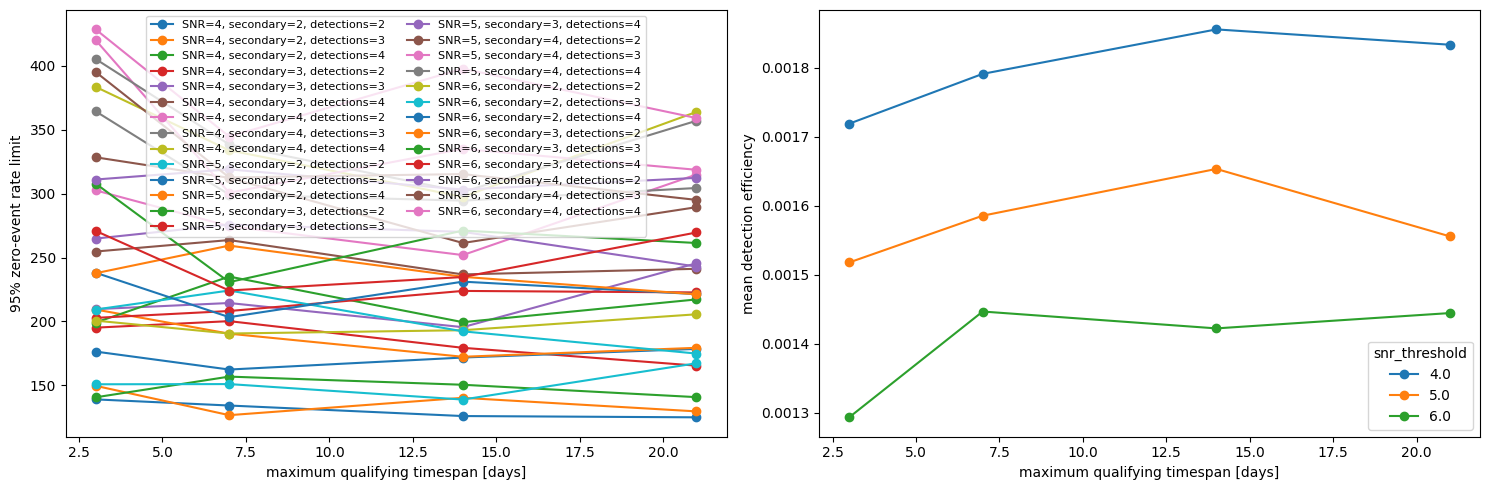

In [7]:
plot_rates = rate_summary[
    (rate_summary['min_detections_primary'] == 1)
    & (rate_summary['min_time_separation_hours'] == 3)
    & (rate_summary['min_fade_rate'] == 0.3)
    & (rate_summary['min_galactic_lat'] == 15)
]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for (snr, secondary, minimum), subset in plot_rates.groupby(
    ['snr_threshold', 'snr_threshold_secondary', 'min_detections']
):
    subset = subset.sort_values('max_timespan_days')
    label = f'SNR={snr:g}, secondary={secondary:g}, detections={int(minimum)}'
    axes[0].plot(subset['max_timespan_days'], subset['rate_95'], marker='o', label=label)
axes[0].set(xlabel='maximum qualifying timespan [days]', ylabel='95% zero-event rate limit')
axes[0].legend(fontsize=8, ncol=2)
pivot = plot_rates.pivot_table(
    index='max_timespan_days', columns='snr_threshold', values='efficiency', aggfunc='mean'
)
pivot.plot(marker='o', ax=axes[1])
axes[1].set(xlabel='maximum qualifying timespan [days]', ylabel='mean detection efficiency')
fig.tight_layout()